# Prueba 01 (Modelo HAHM)

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
import UpROOT.io as io
import UpROOT.config as conf
import UpROOT.plotting.delphes as pt
import UpROOT.pipelines.delphes as pl

In [3]:
ANALYSIS = 'dp01'
cfg = conf.CONFIGURATIONS[ANALYSIS]
DATASET = cfg['raw_dataset']
PDATASET = cfg['flat_dataset']
PLOT_DATA = cfg['plot_data']
TARGET_MASS = None
MASS_RANGE = cfg['mass_range']
FIT_WINDOW = cfg['fit_window']

# Partícula a estudiar (código PDG/Status en Pythia/MadGraph)
PARTICLE_PID = 1023
PARTICLE_STATUS = 23
PARTICLE_LABEL = "Z'"
TAG = f'pid{PARTICLE_PID}_st{PARTICLE_STATUS}'

MIN_MUON_PT = 0.0
ETA_RANGE = (2.0, 5.0)

plot_options = {
    'save': True,
    'data': PLOT_DATA,
    'output_dir': None
}
particle_options = {**plot_options, 'label': PARTICLE_LABEL}

In [4]:
cut = '(PID == 1023) & (Status == 23)' # Código del fotón oscuro zp
BRANCHES = (
    'event_id',
    'object_index',
    'PID',
    'Status',
    'Mass',
    'E',
    'Px',
    'Py',
    'Pz',
    'P',
    'PT',
    'Eta',
    'Phi',
)

In [5]:
df_events = io.load_dataframe(
    branches=None,
    dataset=PDATASET,
    tree_path='Events',
)
df_events.head()

Archivo: hahm01_pandas.root
Árbol seleccionado: Events
Total de eventos: 250,000 eventos


,source_file_id,event_id,source_entry,root_uid,event_number,ReadTime,ProcTime,ProcessID,MPI,event_weight,...,PDF2,n_EFlowTrack,n_Electron,n_Jet,n_MissingET,n_Muon,n_Particle,n_ScalarHT,n_Track,n_Weight
0,0,0,0,0,0,0.238070,0.032934,9999,-1,0.000002,...,inf,2,0,0,1,0,595,1,9,292
1,0,1,1,0,1,0.003865,0.002310,9999,-1,0.000002,...,inf,4,0,0,1,0,768,1,11,292
2,0,2,2,0,2,0.000927,0.000481,9999,-1,0.000002,...,inf,2,0,0,1,0,189,1,4,292
3,0,3,3,0,3,0.042126,0.005983,9999,-1,0.000002,...,inf,16,0,0,1,0,2436,1,57,292
4,0,4,4,0,4,0.004392,0.003015,9999,-1,0.000003,...,inf,7,0,0,1,0,1655,1,44,292


In [6]:
# df_pid = io.load_dataframe(
#     branches=('event_id', 'PID', 'Status'),
#     dataset=PDATASET,
#     tree_path='Particles'
# )
# display(
#     df_pid.groupby(['PID', 'Status']).size()
#     .rename('Particulas')
#     .sort_values(ascending=False)
#     .head(30)
# )
# del df_pid

In [ ]:
df_particle = io.load_dataframe(
    branches=BRANCHES,
    dataset=PDATASET,
    tree_path='Particles',
    cut=cut
)
# df_particle.head(7)

Archivo: hahm01_pandas.root
Árbol seleccionado: Particles


In [ ]:
df_jet = io.load_dataframe(
    dataset=PDATASET,
    tree_path='Jets',
    branches=['event_id', 'object_index', 'PT', 'Eta', 'Phi', 'Mass', 'BTag']
)
df_jet.head()

Archivo: hahm00_pandas.root
Árbol seleccionado: Jets
Total de eventos: 3,007 eventos


,event_id,object_index,PT,Eta,Phi,Mass,BTag
0,4,0,51.844090,-3.343123,2.595220,11.057254,0
1,7,0,26.909838,-2.040212,1.024631,6.014088,0
2,13,0,29.511744,-1.565157,2.862662,3.570057,0
3,18,0,45.236713,3.438823,0.416201,6.336527,0
4,19,0,24.249216,2.616957,2.928521,3.681204,1


In [ ]:
df_met = io.load_dataframe(
    dataset=PDATASET,
    tree_path='MissingET',
    branches=['event_id', 'MET', 'Eta', 'Phi']
)
df_met.head()

Archivo: hahm00_pandas.root
Árbol seleccionado: MissingET
Total de eventos: 10,000 eventos


,event_id,MET,Eta,Phi
0,0,13.338988,-4.072959,-1.004864
1,1,4.499871,-2.139929,-0.370714
2,2,9.756926,2.743701,0.661551
3,3,9.751801,-2.084493,2.022669
4,4,36.882423,3.660398,-0.303877


In [ ]:
analysis = pl.prepare_particle_analysis(
    df_particle,
    pid=PARTICLE_PID,
    status=PARTICLE_STATUS,
    events=df_events
)
particles = analysis['particles']
pairs = analysis['particle_pairs']
summary = analysis['summary']
particle_pairs.head()

,event_id,n_particles,p1_index,p1_pid,p1_status,p1_mass,p1_e,p1_px,p1_py,p1_pz,...,pair_px,pair_py,pair_pz,pair_mass,pair_pt,pair_eta,pair_phi,pair_rapidity,pair_delta_phi,pair_delta_r
0,0,2,3,1023,23,20.0,119.760635,-2.725811,-9.781205,-117.641434,...,0.0,0.0,-171.889519,47.989604,0.0,NaN,0.0,-1.987955,-3.141593,3.233934
1,1,2,3,1023,23,20.0,169.170349,25.093660,-32.202892,162.947510,...,0.0,0.0,788.142761,111.682282,0.0,NaN,0.0,2.652151,-3.141593,3.411667
2,2,2,3,1023,23,20.0,27.107714,-12.035947,4.215072,-13.122395,...,0.0,0.0,-48.756851,50.108349,0.0,NaN,0.0,-0.862173,-3.141593,3.254440
3,3,2,3,1023,23,20.0,48.062695,3.320658,-3.779687,-43.413246,...,0.0,0.0,-1011.726662,99.378111,0.0,NaN,0.0,-3.016032,3.141593,4.414594
4,4,2,3,1023,23,20.0,544.102295,-4.716371,-15.538320,-543.492065,...,0.0,0.0,-2516.491699,62.597872,0.0,NaN,0.0,-4.387192,-3.141593,3.395785


In [ ]:
particles.head()

,event_id,object_index,PID,Status,Mass,E,Px,Py,Pz,P,PT,Eta,Phi
3,0,3,1023,23,20.0,119.760635,-2.725811,-9.781205,-117.641434,118.078827,10.153916,-3.144786,-1.842579
4,0,4,1023,23,20.0,58.702271,2.725811,9.781205,-54.248085,55.190186,10.153916,-2.377501,1.299014
1416,1,3,1023,23,20.0,169.170349,25.093660,-32.202892,162.947510,167.983948,40.825459,2.092605,-0.908845
1417,1,4,1023,23,20.0,626.845947,-25.093660,32.202892,625.195251,626.526794,40.825459,3.422970,2.232748
3382,2,3,1023,23,20.0,27.107714,-12.035947,4.215072,-13.122395,18.298309,12.752680,-0.901726,2.804734


In [ ]:
display(pd.Series(summary, name='resumen'))

pid                                         [1023]
status_filter                                   23
n_total_events                               10000
n_particle_rows_all_statuses                 19960
n_particle_rows_selected                     19960
n_events_with_particle                        9980
n_events_with_exactly_two                     9980
fraction_total_events_with_particle          0.998
multiplicity_counts                      {2: 9980}
status_counts                          {23: 19960}
mass_mean_gev                                 20.0
mass_std_gev                                   0.0
mass_median_gev                               20.0
n_particle_pairs                              9980
Name: resumen, dtype: object

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\particle_multiplicity_pid1023_st23.png.


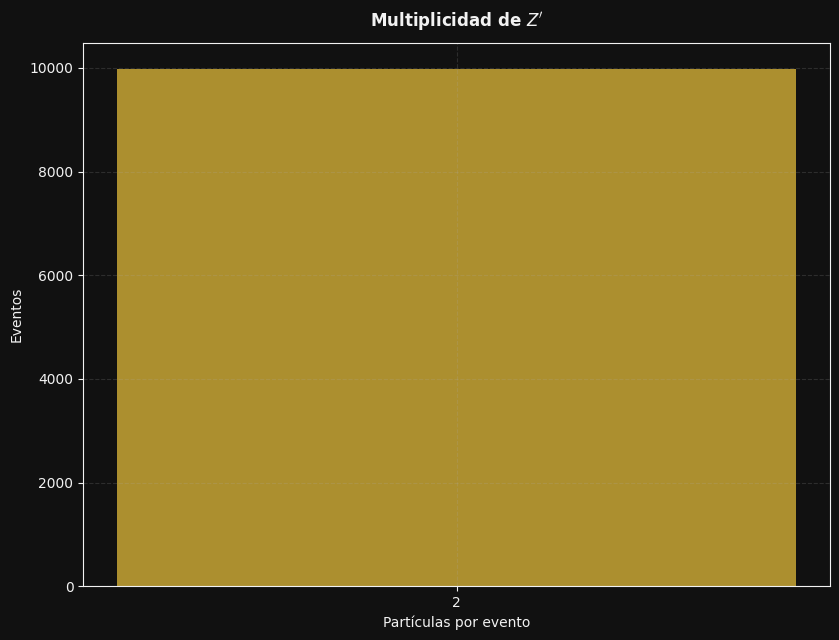

(<Figure size 850x650 with 1 Axes>,
 <Axes: title={'center': "Multiplicidad de $Z'$"}, xlabel='Partículas por evento', ylabel='Eventos'>)

In [ ]:
pt.plot_mediator_multiplicity(
    particles,
    filename=f'particle_multiplicity_{TAG}',
    **particle_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\particle_pair_kinematics_pid1023_st23.png.


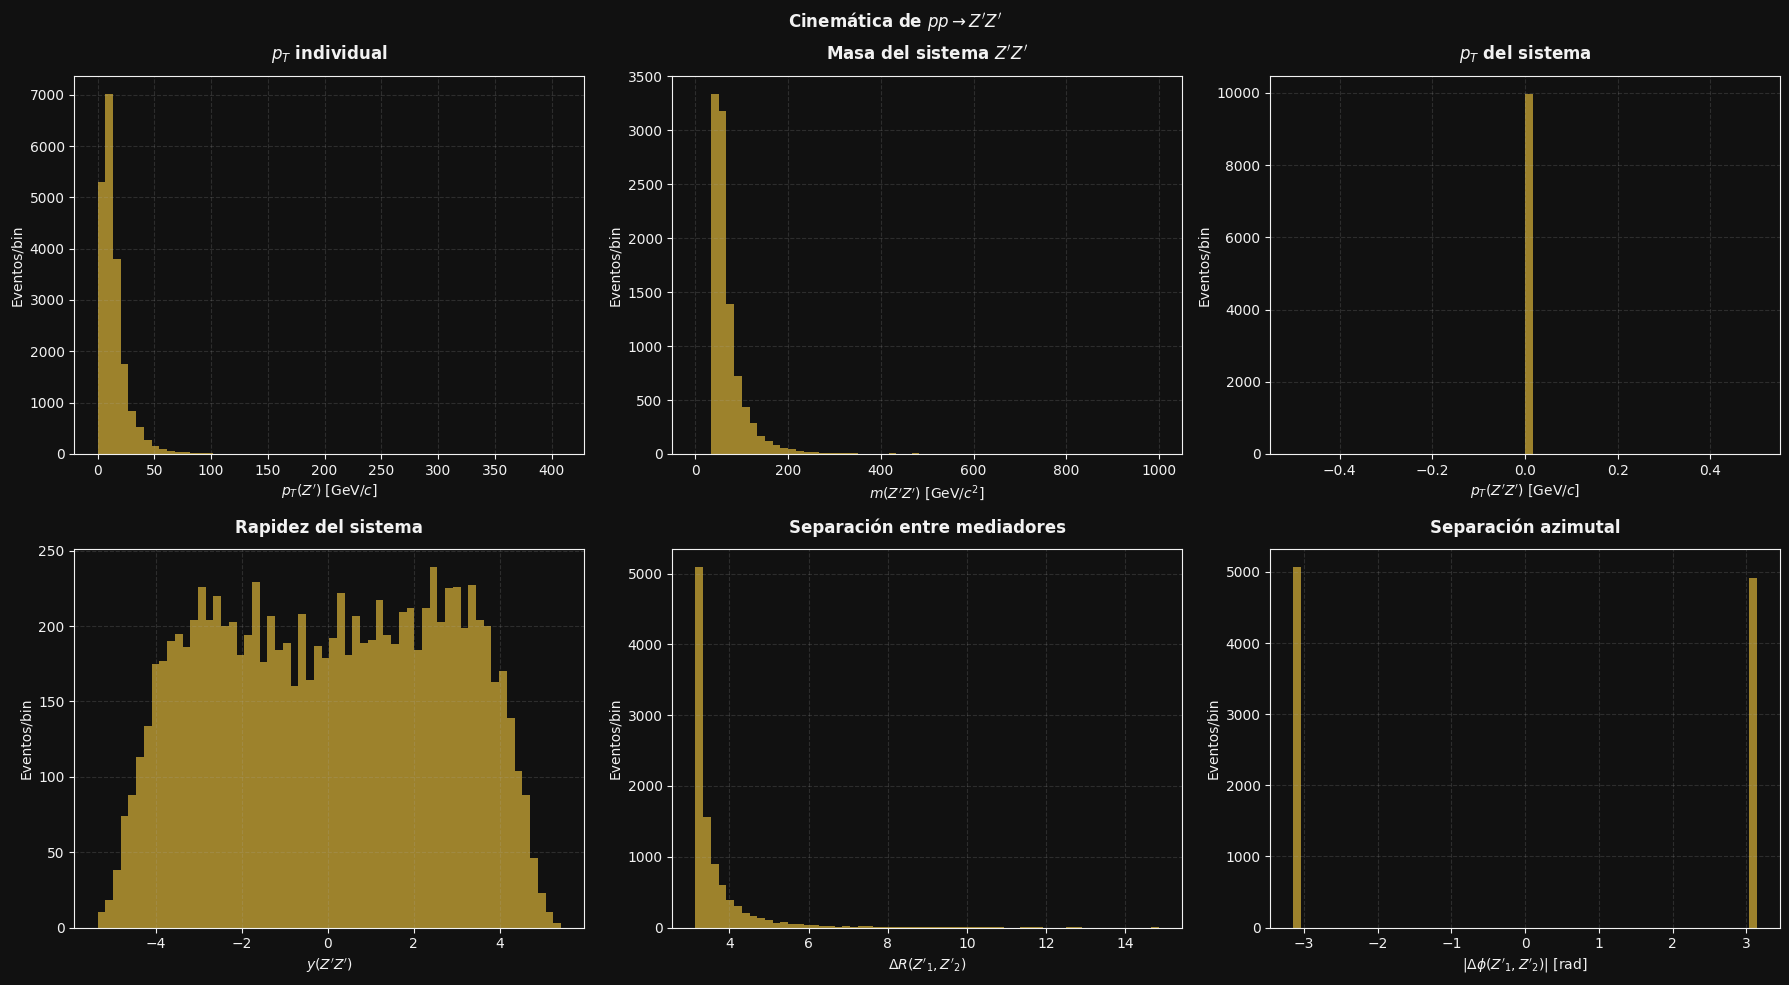

(<Figure size 1800x1000 with 6 Axes>,
 array([[<Axes: title={'center': '$p_T$ individual'}, xlabel="$p_T(Z')$ [GeV/$c$]", ylabel='Eventos/bin'>,
         <Axes: title={'center': "Masa del sistema $Z'Z'$"}, xlabel="$m(Z'Z')$ [GeV/$c^2$]", ylabel='Eventos/bin'>,
         <Axes: title={'center': '$p_T$ del sistema'}, xlabel="$p_T(Z'Z')$ [GeV/$c$]", ylabel='Eventos/bin'>],
        [<Axes: title={'center': 'Rapidez del sistema'}, xlabel="$y(Z'Z')$", ylabel='Eventos/bin'>,
         <Axes: title={'center': 'Separación entre mediadores'}, xlabel="$\\Delta R(Z'_1,Z'_2)$", ylabel='Eventos/bin'>,
         <Axes: title={'center': 'Separación azimutal'}, xlabel="$|\\Delta\\phi(Z'_1,Z'_2)|$ [rad]", ylabel='Eventos/bin'>]],
       dtype=object))

In [ ]:
pt.plot_mediator_pair_observables(
    particle_pairs,
    bins=60,
    pair_mass_range=(0.0, 1000.0),
    filename=f'particle_pair_kinematics_{TAG}',
    **particle_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\event_multiplicities.png.


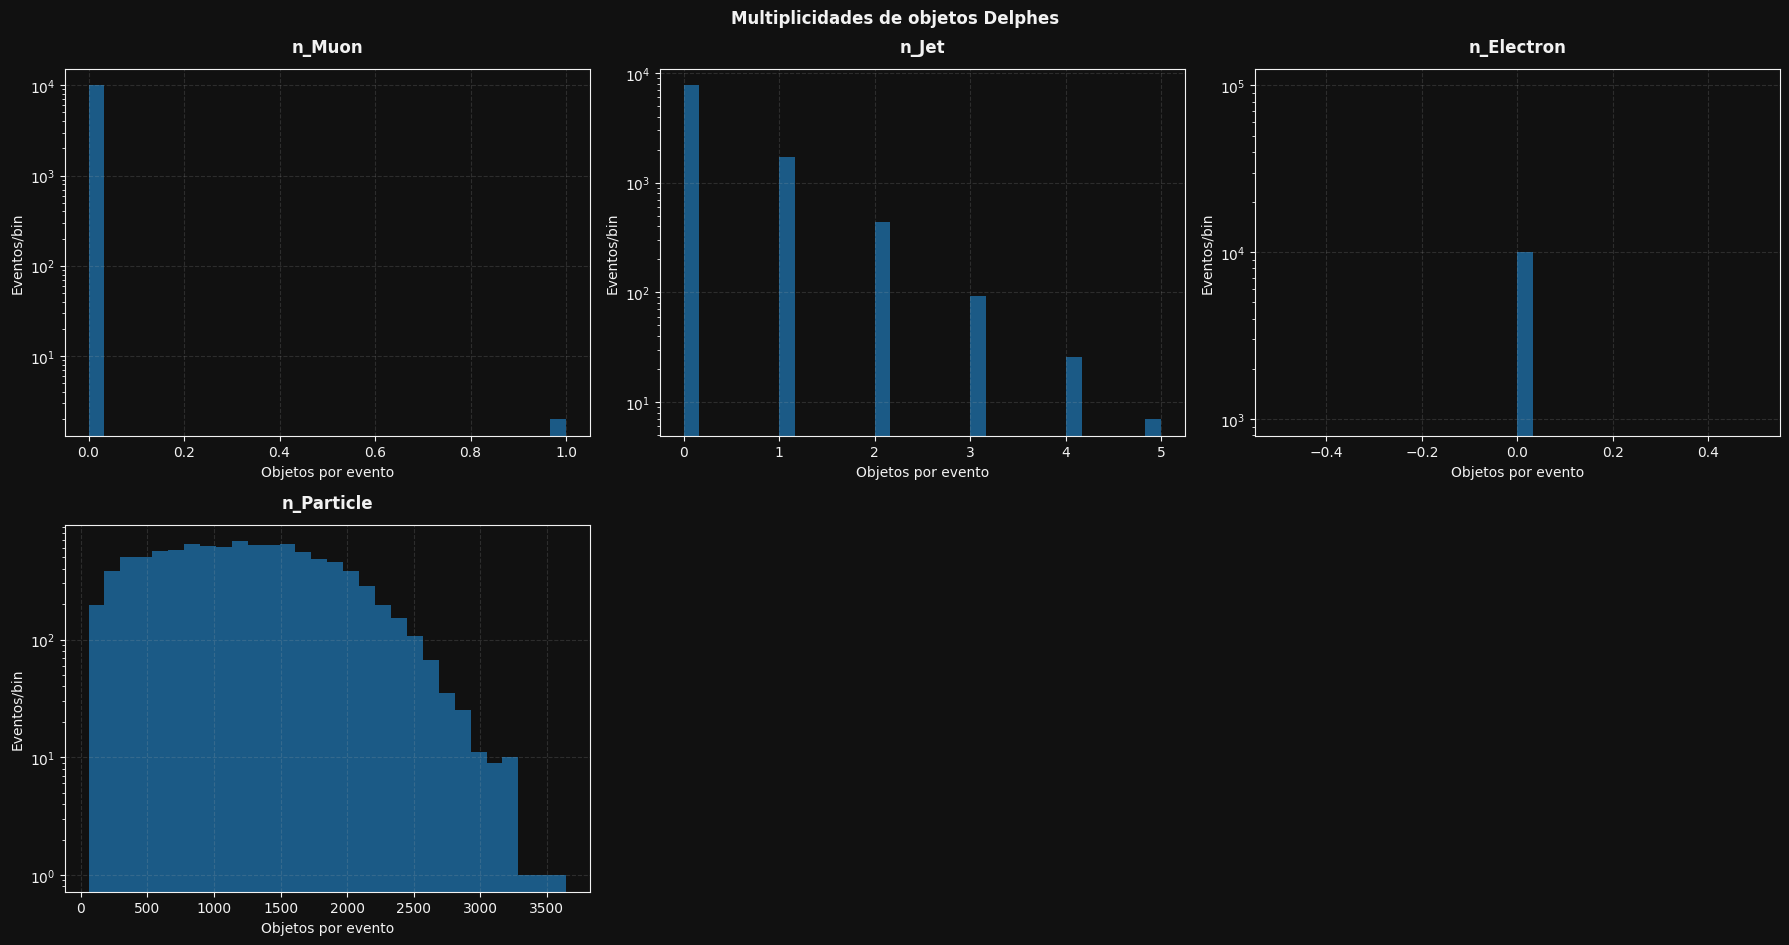

(<Figure size 1800x960 with 6 Axes>,
 array([[<Axes: title={'center': 'n_Muon'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Jet'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: title={'center': 'n_Electron'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>],
        [<Axes: title={'center': 'n_Particle'}, xlabel='Objetos por evento', ylabel='Eventos/bin'>,
         <Axes: >, <Axes: >]], dtype=object))

In [ ]:
pt.plot_event_multiplicities(
    df_events,
    filename='event_multiplicities',
    **plot_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\zp_kinematics.png.


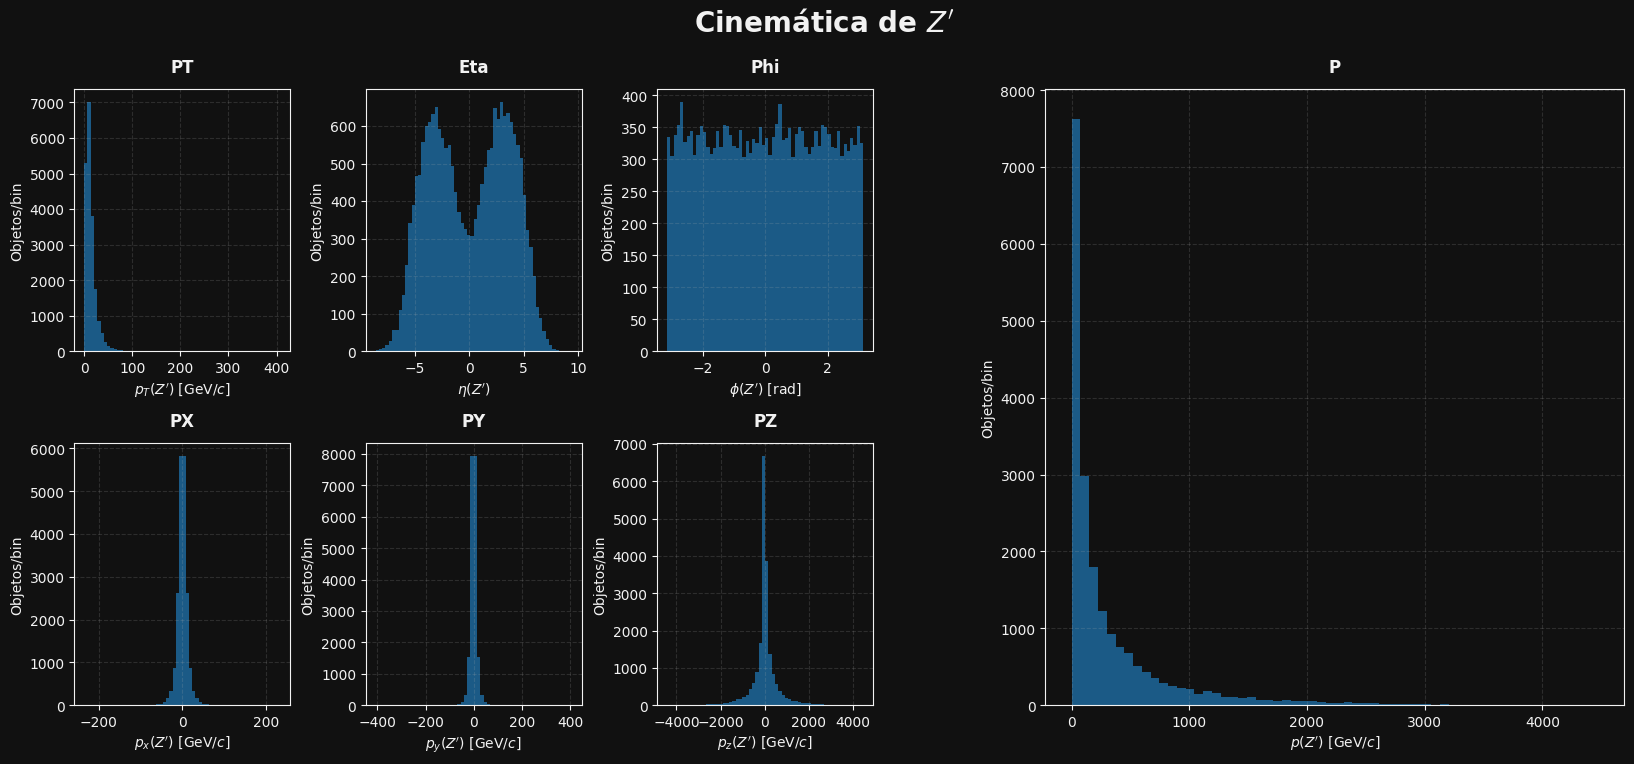

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel="$p_T(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel="$\\eta(Z')$", ylabel='Objetos/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel="$\\phi(Z')$ [rad]", ylabel='Objetos/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel="$p_x(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel="$p_y(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel="$p_z(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel="$p(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>})

In [ ]:
pt.plot_particle_kinematics(
    particles, 
    bins=60, 
    filename="zp_kinematics",
    **particle_options
)

c:\Users\mario\Documents\PF\MadGraph\UpROOT\styles.py:165: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\particle_kinematics_TAG_split.png.


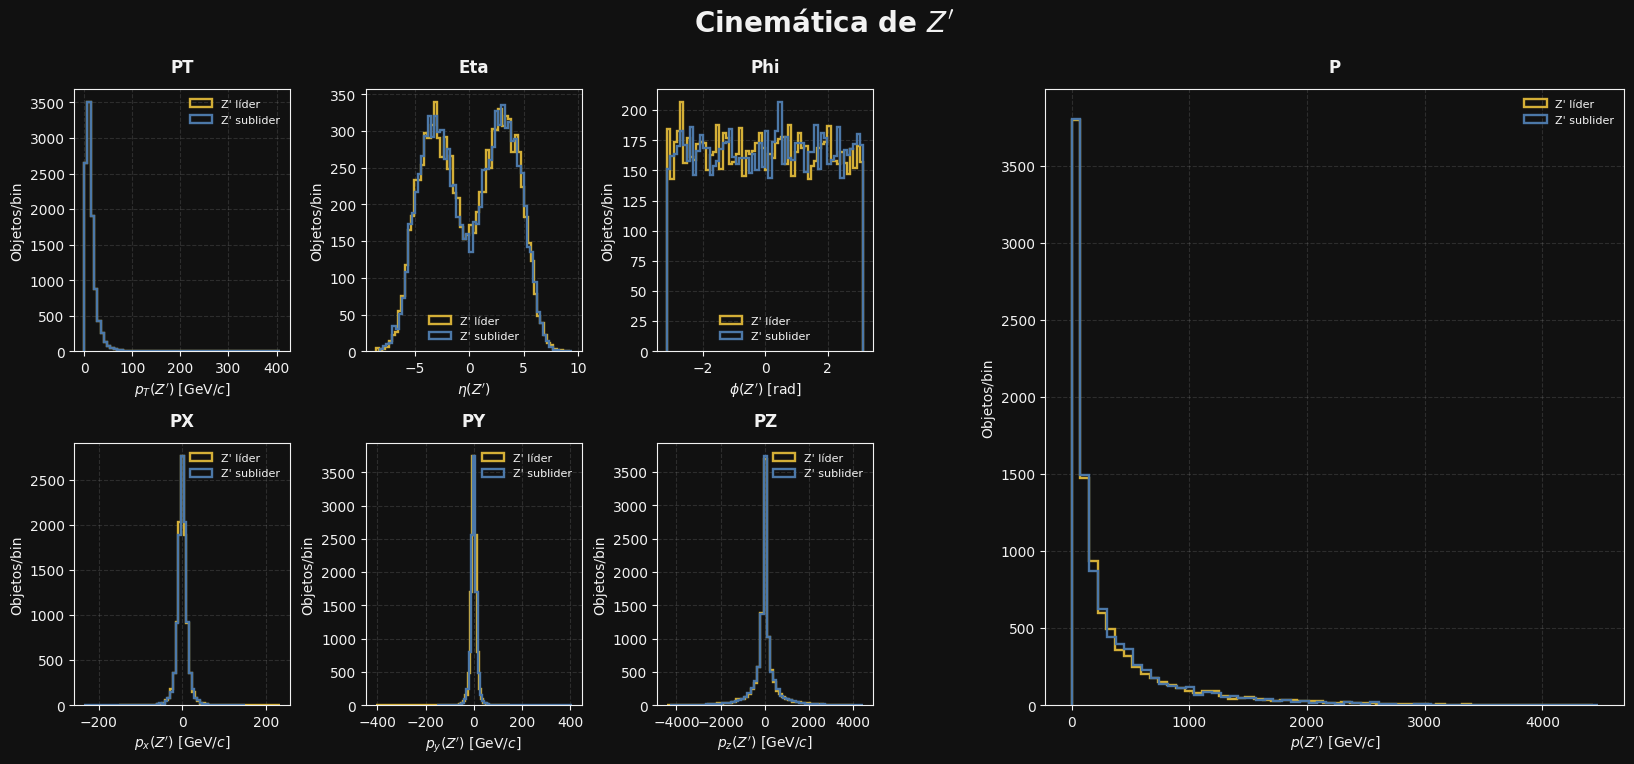

(<Figure size 2000x800 with 7 Axes>,
 {'PT': <Axes: title={'center': 'PT'}, xlabel="$p_T(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'Eta': <Axes: title={'center': 'Eta'}, xlabel="$\\eta(Z')$", ylabel='Objetos/bin'>,
  'Phi': <Axes: title={'center': 'Phi'}, xlabel="$\\phi(Z')$ [rad]", ylabel='Objetos/bin'>,
  'PX': <Axes: title={'center': 'PX'}, xlabel="$p_x(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'PY': <Axes: title={'center': 'PY'}, xlabel="$p_y(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'PZ': <Axes: title={'center': 'PZ'}, xlabel="$p_z(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>,
  'P': <Axes: title={'center': 'P'}, xlabel="$p(Z')$ [GeV/$c$]", ylabel='Objetos/bin'>})

In [ ]:
pt.plot_particle_kinematics(
    particles, 
    bins=60,
    split_rank=True,
    filename="particle_kinematics_{TAG}_split",
    **plot_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\particle_mass_pid1023_st23.png.


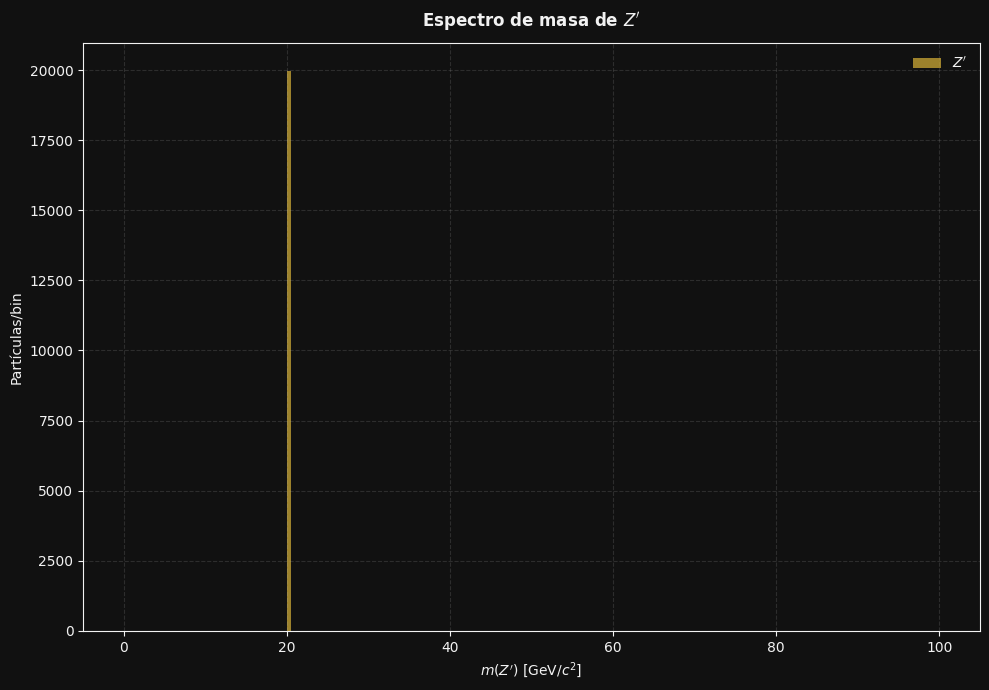

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': "Espectro de masa de $Z'$"}, xlabel="$m(Z')$ [GeV/$c^2$]", ylabel='Partículas/bin'>)

In [ ]:
pt.plot_particle_mass(
    particles,
    bins=200,
    mass_range=MASS_RANGE,
    log_x=False,
    log_y=False,
    filename=f'particle_mass_{TAG}',
    **particle_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\particle_pair_mass_pid1023_st23.png.


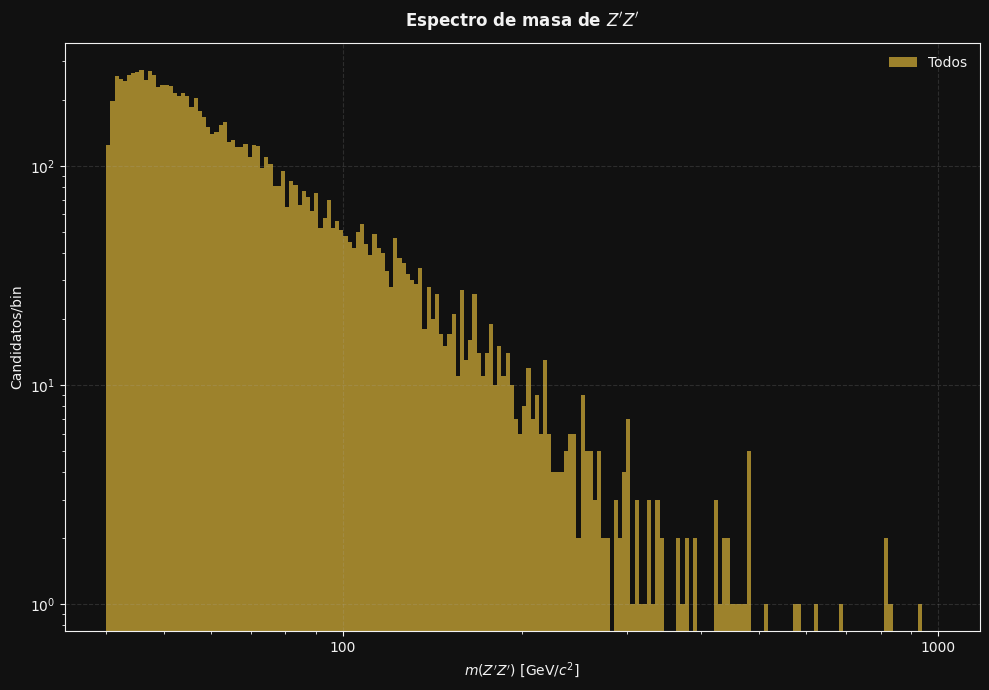

(<Figure size 1000x700 with 1 Axes>,
 <Axes: title={'center': "Espectro de masa de $Z'Z'$"}, xlabel="$m(Z'Z')$ [GeV/$c^2$]", ylabel='Candidatos/bin'>)

In [ ]:
pt.plot_particle_pair_mass(
    particle_pairs,
    bins=200,
    log_x=True,
    log_y=True,
    mass_range=(0.0, 1000.0),
    filename=f'particle_pair_mass_{TAG}',
    **particle_options
)

Guardado en: C:\Users\mario\Documents\PF\MadGraph\assets\images\delphes\dp_model\c00\jet_kinematics_pid1023_st23.png.


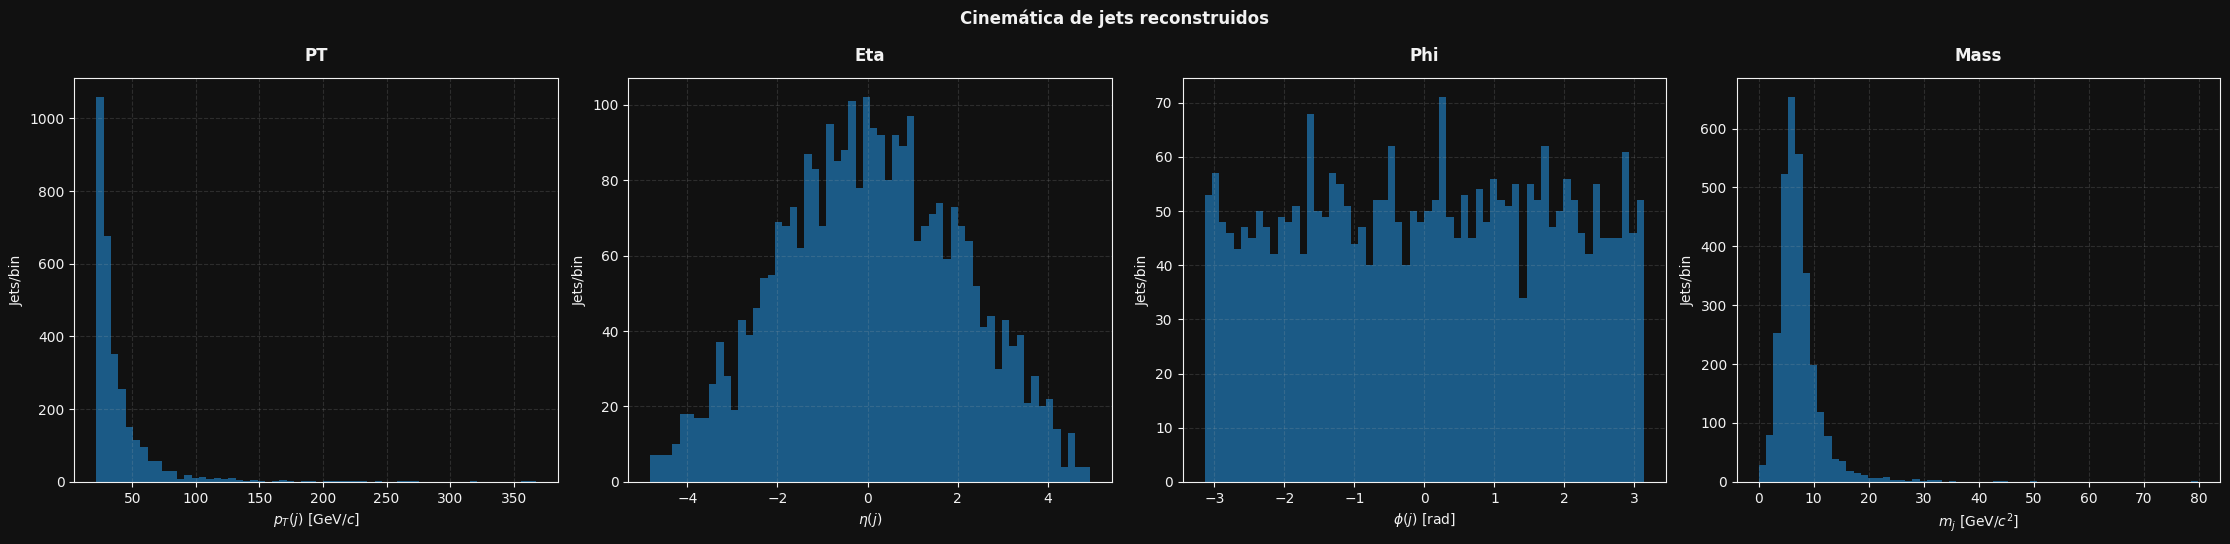

(<Figure size 2240x550 with 4 Axes>,
 array([[<Axes: title={'center': 'PT'}, xlabel='$p_T(j)$ [GeV/$c$]', ylabel='Jets/bin'>,
         <Axes: title={'center': 'Eta'}, xlabel='$\\eta(j)$', ylabel='Jets/bin'>,
         <Axes: title={'center': 'Phi'}, xlabel='$\\phi(j)$ [rad]', ylabel='Jets/bin'>,
         <Axes: title={'center': 'Mass'}, xlabel='$m_j$ [GeV/$c^2$]', ylabel='Jets/bin'>]],
       dtype=object))

In [ ]:
pt.plot_jet_kinematics(
    df_jet,
    bins=60,
    filename=f'jet_kinematics_{TAG}',
    **plot_options
)